In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("x_test :", x_test.shape, x_test.dtype)
print("y_test :", y_test.shape, y_test.dtype)


x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test : (10000, 28, 28) uint8
y_test : (10000,) uint8


In [3]:
# Normalize data
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("After normalization:")
print("min/max train:", x_train.min(), x_train.max())
print("min/max test :", x_test.min(), x_test.max())


After normalization:
min/max train: 0.0 1.0
min/max test : 0.0 1.0


In [5]:
# Flatten data
x_train_flat = x_train.reshape(len(x_train), -1)  # (60000, 784)
x_test_flat  = x_test.reshape(len(x_test), -1)    # (10000, 784)

print("x_train_flat:", x_train_flat.shape)
print("x_test_flat :", x_test_flat.shape)


x_train_flat: (60000, 784)
x_test_flat : (10000, 784)


In [7]:
def gaussian_noise(x, mean=0.0, std=0.3):
   
    noise = np.random.normal(loc=mean, scale=std, size=x.shape).astype(np.float32)
    x_noisy = x + noise
    return np.clip(x_noisy, 0.0, 1.0)

def salt_pepper_noise(x, amount=0.1, salt_vs_pepper=0.5):
  
    x_noisy = x.copy()
    rnd = np.random.rand(*x.shape)

    # mask of corrupted pixels
    corrupt = rnd < amount

    # among corrupted: decide salt vs pepper
    rnd2 = np.random.rand(*x.shape)
    salt = corrupt & (rnd2 < salt_vs_pepper)
    pepper = corrupt & (rnd2 >= salt_vs_pepper)

    x_noisy[salt] = 1.0
    x_noisy[pepper] = 0.0
    return x_noisy


In [9]:
import numpy as np

def mixed_nois(x_clean, gauss_std=0.35, sp_amount=0.15, mix_ratio=0.5, seed=42):
    
    rng = np.random.default_rng(seed)
    n = len(x_clean)
    idx = rng.permutation(n)
    k = int(n * mix_ratio)

    gauss_idx = idx[:k]
    sp_idx    = idx[k:]

    x_noisy = x_clean.copy()

    # Apply Gaussian to subset
    x_noisy[gauss_idx] = gaussian_noise(x_clean[gauss_idx], std=gauss_std)

    # Apply Salt & Pepper to subset
    x_noisy[sp_idx] = salt_pepper_noise(x_clean[sp_idx], amount=sp_amount)

    mask_gauss = np.zeros(n, dtype=bool)
    mask_gauss[gauss_idx] = True

    return x_noisy, mask_gauss

# Train mixed 
x_train_noisy_mix, train_mask_gauss = mixed_nois(
    x_train, gauss_std=0.35, sp_amount=0.15, mix_ratio=0.5, seed=1
)

# ---- Test sets (separate + mixed) ----
x_test_noisy_gauss = gaussian_noise(x_test, std=0.35)
x_test_noisy_sp    = salt_pepper_noise(x_test, amount=0.15)
x_test_noisy_mix, test_mask_gauss = mixed_nois(
    x_test, gauss_std=0.35, sp_amount=0.15, mix_ratio=0.5, seed=2
)

# Flatten for Dense AE
x_train_flat      = x_train.reshape(len(x_train), -1)
x_train_noisy_flat= x_train_noisy_mix.reshape(len(x_train_noisy_mix), -1)

x_test_flat       = x_test.reshape(len(x_test), -1)
x_test_gauss_flat = x_test_noisy_gauss.reshape(len(x_test_noisy_gauss), -1)
x_test_sp_flat    = x_test_noisy_sp.reshape(len(x_test_noisy_sp), -1)
x_test_mix_flat   = x_test_noisy_mix.reshape(len(x_test_noisy_mix), -1)

print("Train noisy mix flat:", x_train_noisy_flat.shape)
print("Test gauss flat     :", x_test_gauss_flat.shape)
print("Test sp flat        :", x_test_sp_flat.shape)
print("Test mix flat       :", x_test_mix_flat.shape)


Train noisy mix flat: (60000, 784)
Test gauss flat     : (10000, 784)
Test sp flat        : (10000, 784)
Test mix flat       : (10000, 784)


In [11]:
# Create Autoencoder Model
import tensorflow as tf
from tensorflow.keras import layers, Model

def dense_autoencoder(input_dim=784, latent_dim=64, use_batchnorm=False, dropout_rate=0.0):
   
    inp = layers.Input(shape=(input_dim,))

    # Encoder
    x = layers.Dense(256)(inp)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(latent_dim)(x)  # Bottleneck / Latent Represemtation 
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    # Decoder
    x = layers.Dense(256)(x)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    out = layers.Dense(input_dim, activation="sigmoid")(x)

    model = Model(inp, out, name="dense_autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="mse")
    return model

ae = dense_autoencoder(input_dim=784, latent_dim=64, use_batchnorm=False, dropout_rate=0.0)
ae.summary()


Model: "dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 435,536 (1.66 MB)

 Trainable params: 435,536 (1.66 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

history = ae.fit(
    x_train_noisy_flat, x_train_flat,
    validation_split=0.1,
    epochs=20,
    batch_size=256,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

mse_gauss = ae.evaluate(x_test_gauss_flat, x_test_flat, verbose=0)
mse_sp    = ae.evaluate(x_test_sp_flat,    x_test_flat, verbose=0)
mse_mix   = ae.evaluate(x_test_mix_flat,   x_test_flat, verbose=0)

print(f"MSE (Test Gaussian)      : {mse_gauss:.6f}")
print(f"MSE (Test Salt & Pepper) : {mse_sp:.6f}")
print(f"MSE (Test Mixed)         : {mse_mix:.6f}")


Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.0575 - val_loss: 0.0329
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0261 - val_loss: 0.0212
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.0193 - val_loss: 0.0178
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0165 - val_loss: 0.0157
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0149 - val_loss: 0.0146
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0140 - val_loss: 0.0139
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0134 - val_loss: 0.0135
Epoch 8/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - loss: 0.0129 - val_loss: 0.0133
Epoch 9/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0124 - val_loss: 0.0126
Epoch 10/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0120 - val_loss: 0.0123
Epoch 11/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0117 - val_loss: 0.0120
Epoch 12/20
211/211 ━━━━━━━━━━━━━━━━━━━━

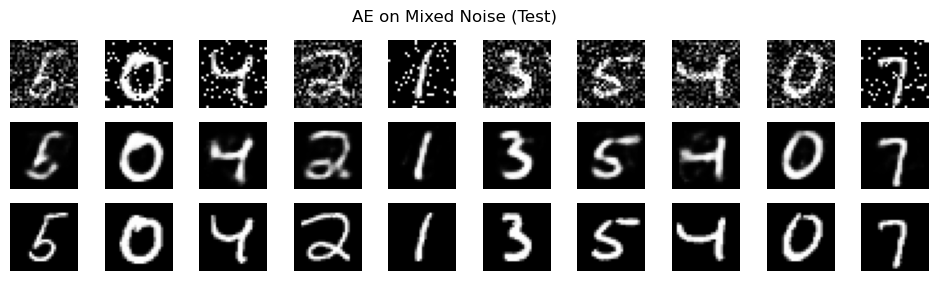

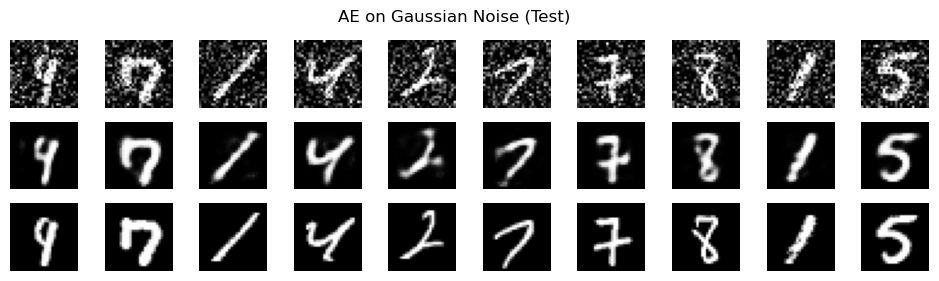

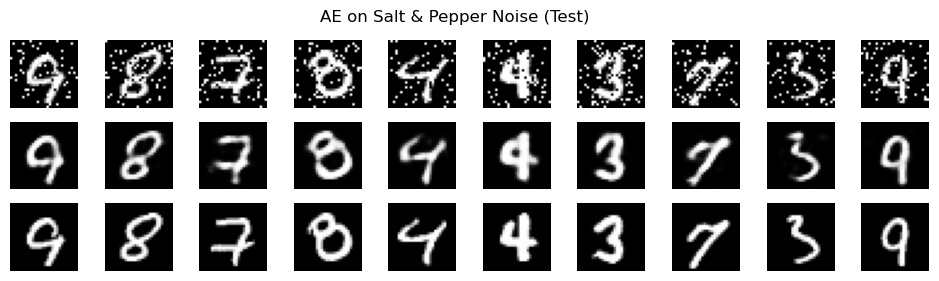

In [17]:
# Visual Evaluation

def show_reconstructions(model, x_noisy_flat, x_clean, n=10, title="Reconstructions"):
    idx = np.random.choice(len(x_clean), size=n, replace=False)
    recon = model.predict(x_noisy_flat[idx], verbose=0).reshape(n, 28, 28)

    plt.figure(figsize=(12, 3))
    for i in range(n):
        # Noisy
        plt.subplot(3, n, i+1)
        plt.imshow(x_noisy_flat[idx[i]].reshape(28,28), cmap="gray")
        plt.axis("off")
        if i == 0: plt.ylabel("Noisy")

        # Recon
        plt.subplot(3, n, n+i+1)
        plt.imshow(recon[i], cmap="gray")
        plt.axis("off")
        if i == 0: plt.ylabel("Recon")

        # Clean
        plt.subplot(3, n, 2*n+i+1)
        plt.imshow(x_clean[idx[i]], cmap="gray")
        plt.axis("off")
        if i == 0: plt.ylabel("Clean")

    plt.suptitle(title)
    plt.show()

show_reconstructions(ae, x_test_mix_flat, x_test, n=10, title="AE on Mixed Noise (Test)")
show_reconstructions(ae, x_test_gauss_flat, x_test, n=10, title="AE on Gaussian Noise (Test)")
show_reconstructions(ae, x_test_sp_flat, x_test, n=10, title="AE on Salt & Pepper Noise (Test)")


In [19]:
experiments = [
    # name, hidden_units (encoder), latent_dim, batchnorm, dropout
    ("AE_small",   [128],      32,  False, 0.0),
    ("AE_base",    [256],      64,  False, 0.0),
    ("AE_deep",    [512, 256], 64,  False, 0.0),
    ("AE_wide",    [512],      128, False, 0.0),

    # BatchNorm variants
    ("AE_base_BN", [256],      64,  True,  0.0),

    # Dropout variants
    ("AE_base_DO", [256],      64,  False, 0.2),

    # BN + Dropout
    ("AE_base_BN_DO", [256],   64,  True,  0.2),
]
len(experiments)


7

In [23]:
# Flixible Autoencoder to experiment

import tensorflow as tf
from tensorflow.keras import layers, Model

def autoencoder_flexible(input_dim, hidden_units, latent_dim,
                                     use_batchnorm=False, dropout_rate=0.0):
   
    inp = layers.Input(shape=(input_dim,))
    x = inp

    # Encoder
    for u in hidden_units:
        x = layers.Dense(u)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)

    # Latent
    x = layers.Dense(latent_dim)(x)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    # Decoder (mirror)
    for u in reversed(hidden_units):
        x = layers.Dense(u)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)

    out = layers.Dense(input_dim, activation="sigmoid")(x)

    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model


In [25]:
# Evaluate autoencoder on experimental list
import pandas as pd
from tensorflow.keras.callbacks import EarlyStopping

def run_experiment(name, hidden_units, latent_dim, use_batchnorm, dropout_rate,
                   epochs=20, batch_size=256):
    model = autoencoder_flexible(
        input_dim=784,
        hidden_units=hidden_units,
        latent_dim=latent_dim,
        use_batchnorm=use_batchnorm,
        dropout_rate=dropout_rate
    )

    callbacks = [EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

    history = model.fit(
        x_train_noisy_flat, x_train_flat,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        callbacks=callbacks,
        verbose=0
    )

    mse_gauss = model.evaluate(x_test_gauss_flat, x_test_flat, verbose=0)
    mse_sp    = model.evaluate(x_test_sp_flat,    x_test_flat, verbose=0)
    mse_mix   = model.evaluate(x_test_mix_flat,   x_test_flat, verbose=0)

    best_val = float(np.min(history.history["val_loss"]))

    return {
        "name": name,
        "hidden_units": str(hidden_units),
        "latent_dim": latent_dim,
        "batchnorm": use_batchnorm,
        "dropout": dropout_rate,
        "best_val_mse": best_val,
        "test_mse_gauss": float(mse_gauss),
        "test_mse_sp": float(mse_sp),
        "test_mse_mix": float(mse_mix),
        "epochs_ran": len(history.history["loss"])
    }, model

results = []
trained_models = {}

for exp in experiments:
    name, hidden_units, latent_dim, bn, do = exp
    row, model = run_experiment(name, hidden_units, latent_dim, bn, do)
    results.append(row)
    trained_models[name] = model
    print(f"Done: {name} | mix MSE={row['test_mse_mix']:.6f}")

df = pd.DataFrame(results).sort_values("test_mse_mix")
df.reset_index(drop=True, inplace=True)
df


Done: AE_small | mix MSE=0.013901
Done: AE_base | mix MSE=0.010169
Done: AE_deep | mix MSE=0.010627
Done: AE_wide | mix MSE=0.008543
Done: AE_base_BN | mix MSE=0.009339
Done: AE_base_DO | mix MSE=0.015839
Done: AE_base_BN_DO | mix MSE=0.014783


,name,hidden_units,latent_dim,batchnorm,dropout,best_val_mse,test_mse_gauss,test_mse_sp,test_mse_mix,epochs_ran
0,AE_wide,[512],128,False,0.0,0.008812,0.008702,0.008410,0.008543,20
1,AE_base_BN,[256],64,True,0.0,0.009605,0.009423,0.009223,0.009339,20
2,AE_base,[256],64,False,0.0,0.010513,0.010346,0.009986,0.010169,20
3,AE_deep,"[512, 256]",64,False,0.0,0.010903,0.010636,0.010603,0.010627,20
4,AE_small,[128],32,False,0.0,0.014325,0.014089,0.013764,0.013901,20
5,AE_base_BN_DO,[256],64,True,0.2,0.015119,0.014957,0.014642,0.014783,20
6,AE_base_DO,[256],64,False,0.2,0.016083,0.016060,0.015623,0.015839,20


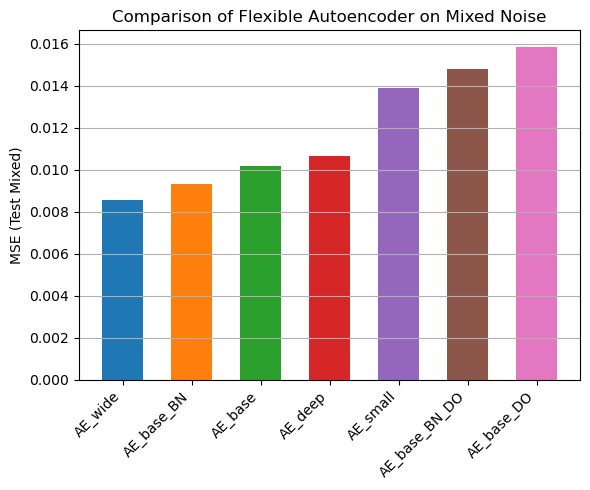

In [29]:
plt.figure(figsize=(6, 5))
plt.bar(
    df["name"],
    df["test_mse_mix"],
    color=plt.cm.tab10(range(len(df))),
    width=0.6
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("MSE (Test Mixed)")
plt.title("Comparison of Flexible Autoencoder on Mixed Noise")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


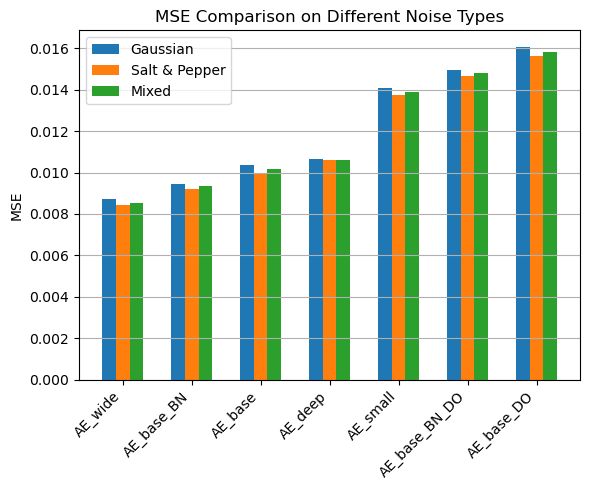

In [31]:
import numpy as np

x = np.arange(len(df))
w = 0.2

plt.figure(figsize=(6, 5))
plt.bar(x - w, df["test_mse_gauss"], width=w, label="Gaussian")
plt.bar(x,     df["test_mse_sp"],    width=w, label="Salt & Pepper")
plt.bar(x + w, df["test_mse_mix"],   width=w, label="Mixed")

plt.xticks(x, df["name"], rotation=45, ha="right")
plt.ylabel("MSE")
plt.title("MSE Comparison on Different Noise Types")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()


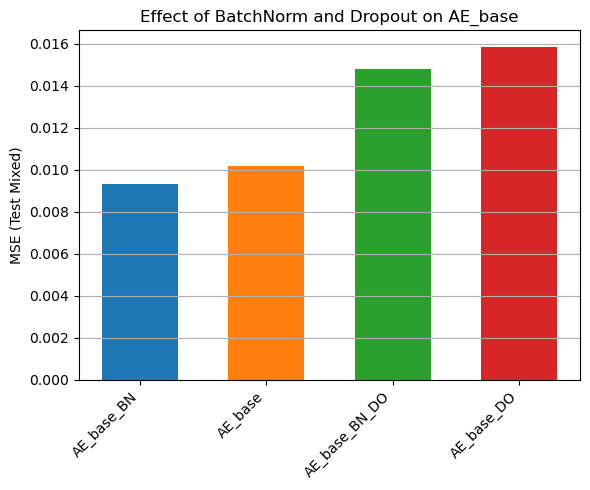

In [33]:
base_df = df[df["name"].str.contains("AE_base")]


plt.figure(figsize=(6, 5))
plt.bar(
    base_df["name"],
    base_df["test_mse_mix"],
    color=plt.cm.tab10(range(len(base_df))),
    width=0.6
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("MSE (Test Mixed)")
plt.title("Effect of BatchNorm and Dropout on AE_base")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

